# Credit Default Prediction Using Machine Learning

*A small investigation into how well we can identify customers at risk of missing a credit card payment.*

I wanted to see how far I could get using relatively straightforward machine learning methods, and whether a more flexible model would actually make a useful difference. I started with logistic regression, explored regularisation to simplify it, and then tested a random forest after spotting a weakness in the initial results.

**The headline results (held-out test set):**

- **Random forest:** ROC–AUC **0.775**, average precision **0.553**.
- **L1 logistic regression:** ROC–AUC **0.758**, average precision **0.526**.
- When each model flagged its highest-risk **20%** of test customers, the random forest caught **27 more defaults** (676 versus 649), with **27 fewer false alarms**.
- A stronger L1 penalty reduced logistic regression from **89 to 36 non-zero encoded coefficients** with almost no change in cross-validated ROC–AUC.

The primary aim is to understand what the models can predict and what we can choose to sacrifice when we favour simplicity or better default detection.

**Data:** [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) - 30,000 credit card accounts from Taiwan, with repayment information from 2005. The target indicates default on the following month's payment. Monetary amounts are in New Taiwan dollars (NT$).

## 1. Loading the data

Each row is a customer and each column is a feature such as credit limit, age, bill amount or repayment status. The dataset already includes whether each customer defaulted, so this is a **supervised classification** problem (using earlier information to predict a yes/no outcome).

The original dataset uses names like `X1` and `X6`; I've kept those names in the code and explained the most important ones as they come up.

In [23]:
%pip -q install ucimlrepo

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, cross_val_score, cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)

In [25]:
credit_data = fetch_ucirepo(id=350)
X = credit_data.data.features
y = credit_data.data.targets.iloc[:, 0]

print("Features:", X.shape)
print("Target:", y.shape)
display(X.head(3))
print("Default rate (%):")
display((y.value_counts(normalize=True) * 100).round(2))

Features: (30000, 23)
Target: (30000,)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000


Default rate (%):


,proportion
Y,
0,77.88
1,22.12


The dataset contains **30,000 observations and 23 input features**. Around **22.1%** of customers defaulted, so the classes aren't balanced. That matters later because a model can look fairly accurate simply by predicting "no default" for everyone.

## 2. Exploring the data

I split the data **before** looking for patterns, keeping 20% aside for testing. That leaves 24,000 customers for exploration and model development, and 6,000 for a later check. I also preserved roughly the same proportion of defaults in each split.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

train_df = X_train.copy()
train_df["default"] = y_train

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (24000, 23)
Test set: (6000, 23)


### 2.1 Does repayment history tell us anything?

`X6` is the most recent repayment-status code. Positive codes represent delays; negative and zero codes have special meanings, so they shouldn't simply be treated as a continuous number of months overdue.

I'd expect longer delays to be linked with higher default rates. To check that, I calculated the rate and the number of customers in each category (the percentages could be misleading if some groups are tiny).

,customers,default_rate_pct
X6,,
-2,2198,12.7
-1,4527,16.6
0,11781,12.8
1,3000,34.4
2,2138,69.4
3,245,76.7
4,58,65.5
5,18,44.4
6,10,60.0


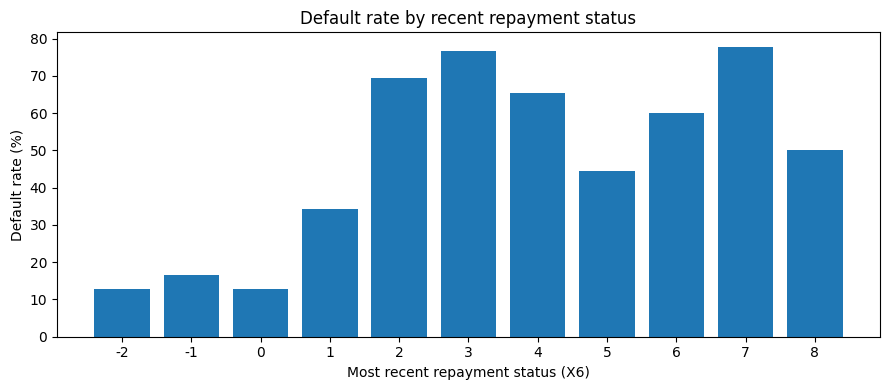

In [27]:
repayment_summary = train_df.groupby("X6")["default"].agg(
    customers="count", default_rate="mean"
)
repayment_summary["default_rate_pct"] = 100 * repayment_summary["default_rate"]
display(repayment_summary[["customers", "default_rate_pct"]].round(1))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(repayment_summary.index.astype(str), repayment_summary["default_rate_pct"])
ax.set(xlabel="Most recent repayment status (X6)",
       ylabel="Default rate (%)",
       title="Default rate by recent repayment status")
plt.tight_layout()
plt.show()

Default rates rise sharply from a one-month delay (**34.4%**) to a two-month delay (**69.4%**) and a three-month delay (**76.7%**). Beyond that, the pattern becomes uneven, but then again the groups are very small. For example, there were only **16 customers** with status code 8 in the training set. For this reason, I wouldn't interpret the apparent drop in risk for that category as a genuine relationship.

### 2.2 What about credit limit?

`X1` is the customer's credit limit. A higher limit could be associated with lower default risk if it reflects the lender's assessment of the customer, but I wanted to see what the data actually showed. I compared both the mean and median because generally credit limits can be very unevenly distributed.

,mean,median
default,,
0,178477.0,150000.0
1,128243.0,90000.0


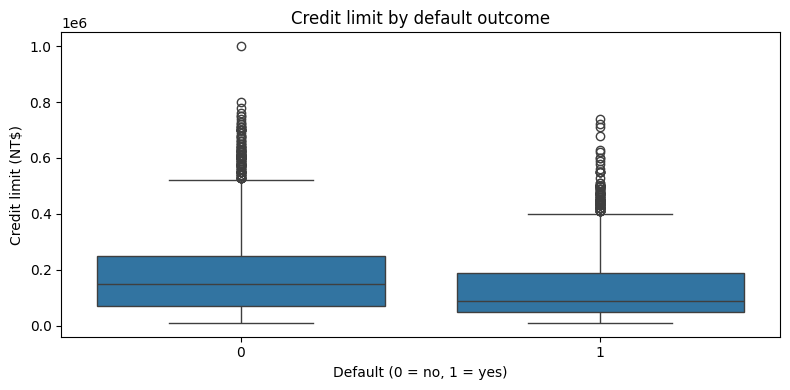

In [28]:
credit_limit_summary = train_df.groupby("default")["X1"].agg(["mean", "median"])
display(credit_limit_summary.round(0))

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=train_df, x="default", y="X1", ax=ax)
ax.set(xlabel="Default (0 = no, 1 = yes)", ylabel="Credit limit (NT$)",
       title="Credit limit by default outcome")
plt.tight_layout()
plt.show()


Customers who defaulted had a lower average credit limit (**NT\$128,243**) than those who didn't (**NT\$178,477**). The median shows the same pattern (**NT\$90,000** vs **NT\$150,000**).

This suggests a relationship between credit limit and default risk, although it doesn't necessarily mean that having a higher credit limit causes better repayment behaviour.



## 3. Data preparation

Before fitting a model, I checked whether the features contained missing values or codes that didn't match the dataset description. I kept inspection separate from cleaning so that any changes had a clear reason.

### 3.1 Checking data quality

Some variables are quantities, while others are categories stored as numbers. This means they need different checks:
*   Ranges and descriptive statistics for numerical features
*   Category frequencies for the coded features







In [29]:
categorical_features = [
    "X2", "X3", "X4", "X6", "X7", "X8", "X9", "X10", "X11"
]
numerical_features = [col for col in X.columns if col not in categorical_features]

print("Null values in training data:", int(X_train.isna().sum().sum()))
print("\nCategorical feature ranges and number of observed codes:")
display(X_train[categorical_features].agg(["min", "max", "nunique"]).T)

print("Education (X3) and marital status (X4) category counts:")
for col in ["X3", "X4"]:
    print(f"{col}:")
    display(X_train[col].value_counts().sort_index())

print("Numerical feature summary:")
display(X_train[numerical_features].describe().T.round(1))

Null values in training data: 0

Categorical feature ranges and number of observed codes:


,min,max,nunique
X2,1,2,2
X3,0,6,7
X4,0,3,4
X6,-2,8,11
X7,-2,8,11
X8,-2,8,11
X9,-2,8,11
X10,-2,8,10
X11,-2,8,10


Education (X3) and marital status (X4) category counts:
X3:


,count
X3,
0,12
1,8455
2,11256
3,3903
4,97
5,235
6,42


X4:


,count
X4,
0,47
1,10892
2,12806
3,255


Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
X1,24000.0,167364.7,129511.3,10000.0,50000.0,140000.0,240000.0,1000000.0
X5,24000.0,35.4,9.2,21.0,28.0,34.0,41.0,75.0
X12,24000.0,51100.5,73510.0,-165580.0,3513.8,22330.0,66966.5,964511.0
X13,24000.0,49012.3,70840.1,-69777.0,2989.8,21107.0,63992.8,983931.0
X14,24000.0,46861.9,68403.9,-61506.0,2652.0,20031.0,60033.8,855086.0
X15,24000.0,43156.7,64046.7,-81334.0,2332.0,19004.5,54386.5,891586.0
X16,24000.0,40164.4,60627.9,-81334.0,1746.0,18102.5,50142.2,927171.0
X17,24000.0,38676.0,59308.7,-339603.0,1225.0,16993.0,48977.2,961664.0
X18,24000.0,5623.6,16148.3,0.0,1000.0,2100.5,5018.2,873552.0
X19,24000.0,5880.0,20253.0,0.0,840.0,2014.0,5000.0,1215471.0


There are **no recorded nulls**, but that doesn't mean every value is straightforward. Education (`X3`) contains undocumented codes **0, 5 and 6**, and marital status (`X4`) contains an undocumented **0**. These are **unknown category codes**, not confirmed missing observations.

The numerical features also contain some large values and negative bill amounts. Those might reflect real account adjustments or credits, so I didn't remove them just because they looked unusual.

### 3.2 Cleaning the documented category issue

I kept the original training and test frames unchanged and made cleaned copies. For education, I grouped the undocumented codes `5` and `6` into code `0`, which I treat as **unknown**. Marital-status code `0` was already its own category, so I left it as it was. No customers were removed.

In [30]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for frame in (X_train_clean, X_test_clean):
    frame["X3"] = frame["X3"].replace({5: 0, 6: 0})

print("Education codes after cleaning:")
display(X_train_clean["X3"].value_counts().sort_index())
print("Original and cleaned training shapes:", X_train.shape, X_train_clean.shape)

Education codes after cleaning:


,count
X3,
0,289
1,8455
2,11256
3,3903
4,97


Original and cleaned training shapes: (24000, 23) (24000, 23)


### 3.3 Making the features usable by the models

I used **one-hot encoding** for the categorical features and **standardisation** for the numerical ones. Repayment status is one-hot encoded because its unusual codes make treating it as an evenly spaced numerical scale questionable.

Both transformations sit inside a Scikit-learn pipeline. That way, each cross-validation fold learns its preprocessing from its own training portion, rather than accidentally learning from the validation data.

In [31]:
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numerical", StandardScaler(), numerical_features)
])

## 4. Starting with a simple classifier

I wanted an initial model that was easy to understand and gave me something sensible to improve on. Logistic regression fits that description becasue it actually estimates the probability of default, rather than just returning a yes/no label.

### 4.1 A baseline that always says "no default"

Before trusting any accuracy score, I compared against a majority-class baseline. Since almost 78% of customers didn't default, this deliberately unhelpful model already gets around **77.9% accuracy**, while detecting **no defaults at all**. As mentioned previously in the "Loading the data" section, this serves as a useful reminder that accuracy on its own doesn't tell the whole story.

In [32]:
dummy_model = DummyClassifier(strategy="most_frequent")
logistic_model = make_pipeline(
    preprocessor, LogisticRegression(max_iter=1000)
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["accuracy", "recall"]

baseline_cv = cross_validate(dummy_model, X_train_clean, y_train,
                             cv=cv, scoring=metrics)
logistic_cv = cross_validate(logistic_model, X_train_clean, y_train,
                             cv=cv, scoring=metrics)

initial_comparison = pd.DataFrame({
    "Model": ["Majority baseline", "Logistic regression"],
    "Accuracy": [baseline_cv["test_accuracy"].mean(),
                 logistic_cv["test_accuracy"].mean()],
    "Recall": [baseline_cv["test_recall"].mean(),
               logistic_cv["test_recall"].mean()]
})
display(initial_comparison.round(3))

,Model,Accuracy,Recall
0,Majority baseline,0.779,0.000
1,Logistic regression,0.820,0.358


### 4.2 How well does logistic regression work?

I used **five-fold stratified cross-validation** on the training data. Each customer is validated using a model fitted without that customer's fold, which gives a more realistic estimate than testing on the same data used for fitting.

As well as accuracy and recall, I measured **precision** (how often a flagged customer really defaults) and **ROC–AUC** (how well the model ranks defaulting customers above non-defaulting ones).

In [33]:
initial_extra_cv = cross_validate(
    logistic_model, X_train_clean, y_train,
    cv=cv, scoring=["precision", "roc_auc"]
)

initial_metrics = pd.Series({
    "Accuracy": logistic_cv["test_accuracy"].mean(),
    "Recall": logistic_cv["test_recall"].mean(),
    "Precision": initial_extra_cv["test_precision"].mean(),
    "ROC-AUC": initial_extra_cv["test_roc_auc"].mean()
}, name="Five-fold mean")
display(initial_metrics.round(3))

,Five-fold mean
Accuracy,0.820
Recall,0.358
Precision,0.679
ROC-AUC,0.769


The first model achieved **82.0% accuracy**, **67.9% precision**, **35.8% recall** and **0.769 ROC–AUC**. It clearly beats the majority baseline at finding defaults. However, there is still concern around recall - at the usual 0.5 threshold, it misses roughly **64% of the customers who default**.

I decided to investigate regularisation first. It might help generalisation and, in the case of L1, make the model simpler.

## 5. Regularisation: is a simpler model enough?

Logistic regression gives each encoded input a coefficient. **L2 regularisation** pushes coefficients towards zero, while **L1** can set some exactly to zero. I used cross-validation to investigate whether changing the penalty affected performance, and whether removing inputs came at a meaningful cost.

Scikit-learn controls the penalty through `C` (**smaller `C` means stronger regularisation**).

### 5.1 L2: changing the penalty strength

I compared five values of `C` and looked at both training and validation ROC–AUC. The idea was to see whether the original model was overfitting and whether stronger shrinkage helped.

,C,Training ROC-AUC,Validation ROC-AUC
0,0.01,0.7735,0.7696
1,0.10,0.7745,0.7694
2,1.00,0.7745,0.7690
3,10.00,0.7746,0.7687
4,100.00,0.7745,0.7687


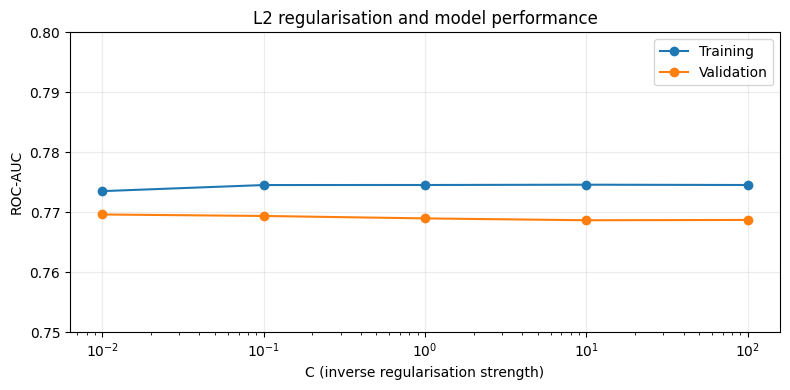

In [34]:
c_values = [0.01, 0.1, 1, 10, 100]

l2_search = GridSearchCV(
    logistic_model,
    param_grid={"logisticregression__C": c_values},
    scoring="roc_auc", cv=cv, return_train_score=True
)
l2_search.fit(X_train_clean, y_train)

l2_results = pd.DataFrame({
    "C": c_values,
    "Training ROC-AUC": l2_search.cv_results_["mean_train_score"],
    "Validation ROC-AUC": l2_search.cv_results_["mean_test_score"]
})
display(l2_results.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(l2_results["C"], l2_results["Training ROC-AUC"],
            marker="o", label="Training")
ax.semilogx(l2_results["C"], l2_results["Validation ROC-AUC"],
            marker="o", label="Validation")
ax.set(xlabel="C (inverse regularisation strength)", ylabel="ROC-AUC",
       title="L2 regularisation and model performance", ylim=(0.75, 0.80))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The strongest L2 setting tested (`C = 0.01`) achieved the highest mean validation ROC–AUC, about **0.770**. But the improvement over the default setting was only about **0.001**. Training and validation scores were also close together, so I didn't see strong evidence of overfitting here. The bigger question became whether L1 could give similar performance with fewer inputs.

### 5.2 L1: reducing the number of coefficients

I repeated the search using L1 regularisation. This time I was interested in **two outcomes**:
*   Validation ROC–AUC
*   How many encoded coefficients ended up exactly at zero



In [35]:
l1_model = make_pipeline(
    preprocessor,
    LogisticRegression(
        penalty="l1", solver="liblinear",
        max_iter=2000, random_state=42
    )
)

l1_search = GridSearchCV(
    l1_model,
    param_grid={"logisticregression__C": c_values},
    scoring="roc_auc", cv=cv, return_train_score=True
)
l1_search.fit(X_train_clean, y_train)

l1_results = pd.DataFrame({
    "C": c_values,
    "Training ROC-AUC": l1_search.cv_results_["mean_train_score"],
    "Validation ROC-AUC": l1_search.cv_results_["mean_test_score"]
})
display(l1_results.round(4))
print("Best C from the grid:", l1_search.best_params_["logisticregression__C"])

,C,Training ROC-AUC,Validation ROC-AUC
0,0.01,0.7663,0.7631
1,0.10,0.7734,0.7690
2,1.00,0.7745,0.7691
3,10.00,0.7748,0.7686
4,100.00,0.7748,0.7679


Best C from the grid: 1


The search selected **`C = 1`**, with validation ROC–AUC around **0.769**. Scores at `C = 0.1` and `C = 1` were almost identical, even though the first applies stronger shrinkage. I counted the coefficients for both settings to see what that small change in `C` actually did.

In [36]:
best_l1 = l1_search.best_estimator_
coefficients_c1 = best_l1.named_steps["logisticregression"].coef_[0]

l1_stronger = make_pipeline(
    preprocessor,
    LogisticRegression(
        penalty="l1", solver="liblinear", C=0.1,
        max_iter=2000, random_state=42
    )
)
l1_stronger.fit(X_train_clean, y_train)
coefficients_c01 = l1_stronger.named_steps["logisticregression"].coef_[0]

sparsity_comparison = pd.DataFrame({
    "C": [1, 0.1],
    "Total encoded coefficients": [len(coefficients_c1), len(coefficients_c01)],
    "Non-zero": [np.count_nonzero(coefficients_c1),
                 np.count_nonzero(coefficients_c01)],
    "Zero": [(coefficients_c1 == 0).sum(), (coefficients_c01 == 0).sum()]
})
display(sparsity_comparison)

c01_cv = l1_search.cv_results_["mean_test_score"][c_values.index(0.1)]
c1_cv = l1_search.cv_results_["mean_test_score"][c_values.index(1)]
print(f"C = 0.1: {c01_cv:.5f} mean validation ROC-AUC")
print(f"C = 1.0: {c1_cv:.5f} mean validation ROC-AUC")

,C,Total encoded coefficients,Non-zero,Zero
0,1.0,89,62,27
1,0.1,89,36,53


C = 0.1: 0.76898 mean validation ROC-AUC
C = 1.0: 0.76910 mean validation ROC-AUC


This was one of the more interesting results. At **`C = 1`**, L1 left **62 of 89** encoded coefficients non-zero. At **`C = 0.1`**, only **36 of 89** remained (**26 fewer**), with validation ROC–AUC changing from **0.76910 to 0.76898**.

The difference in score (**0.00012**) is extremely small compared with the variation between folds (roughly **0.006**). That doesn't prove that the models are statistically equivalent, but it made **`C = 0.1`** a sensible choice if simplicity matters. These are encoded columns, not 36 original customer variables, meaning that removing one repayment-status category doesn't remove the whole repayment-history feature.

## 6. An initial check on the test set

I fitted the selected L1 model (`C = 0.1`) on the full training data, then checked it against the **6,000 customers** held aside at the start. This was meant to be the endpoint of the investigation, but the confusion matrix raised another question.

,0
Accuracy,0.817
Precision,0.665
Recall,0.348
ROC-AUC,0.758


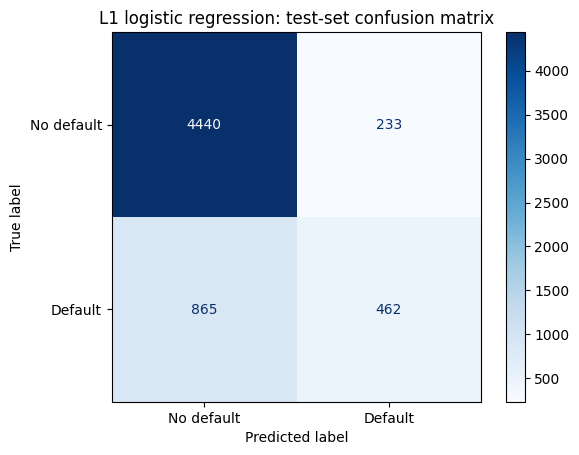

In [37]:
selected_logistic = l1_stronger
logistic_test_predictions = selected_logistic.predict(X_test_clean)
logistic_test_probabilities = selected_logistic.predict_proba(X_test_clean)[:, 1]

logistic_test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, logistic_test_predictions),
    "Precision": precision_score(y_test, logistic_test_predictions),
    "Recall": recall_score(y_test, logistic_test_predictions),
    "ROC-AUC": roc_auc_score(y_test, logistic_test_probabilities)
})
display(logistic_test_metrics.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_test_predictions, labels=[0, 1],
    display_labels=["No default", "Default"], cmap="Blues", values_format="d"
)
plt.title("L1 logistic regression: test-set confusion matrix")
plt.show()

The test ROC-AUC was **0.758**, not far below the **0.769** seen in cross-validation. Accuracy was **81.7%**, but the confusion matrix told the more useful story:

- **462** defaults correctly identified; **865** missed.
- **233** customers incorrectly flagged; **4,440** correctly identified as non-defaulting.
- **Recall: 34.8%** at the standard 0.5 threshold.

So the model could rank risk reasonably well, but at its default threshold it still missed almost **2/3 of actual defaults**. I didn't want to stop at a headline accuracy figure while that weakness was unexplored.

**Important evaluation caveat:** I had now looked at the test set. The remaining experiments use cross-validation on the training data to make comparisons, but the later test comparison isn't a completely untouched, blind final evaluation.

## 7. Could I detect more defaults?

I looked at two possible improvements: **use the logistic regression scores differently**, then **try a different model**. Both of these basically
ask if catching more defaults comes with too many false alarms.

### 7.1 Adjusting the classification threshold

Logistic regression normally predicts "default" when its probability estimate is at least **0.5**. That's a convention, not necessarily the best rule for this task. I compared lower thresholds using **out-of-fold training predictions** where each customer's score comes from a model fitted without that customer's fold.

In [38]:
train_probabilities = cross_val_predict(
    selected_logistic, X_train_clean, y_train,
    cv=cv, method="predict_proba"
)[:, 1]

threshold_rows = []
for threshold in [0.50, 0.40, 0.30, 0.20]:
    predicted = (train_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, predicted, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Defaults caught": tp,
        "Defaults missed": fn,
        "False alarms": fp,
        "Precision": precision_score(y_train, predicted),
        "Recall": recall_score(y_train, predicted)
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

,Threshold,Defaults caught,Defaults missed,False alarms,Precision,Recall
0,0.5,1880,3429,901,0.676,0.354
1,0.4,2189,3120,1229,0.640,0.412
2,0.3,2638,2671,1981,0.571,0.497
3,0.2,3284,2025,3912,0.456,0.619


Reducing the threshold from **0.5 to 0.3** caught **758 extra defaults** in the cross-validated training predictions (**2,638 versus 1,880**). Recall improved from **35.4% to 49.7%**, but false alarms rose from **901 to 1,981**, and precision dropped from **67.6% to 57.1%**.

That's an important trade-off rather than a free improvement. With no real business costs for missed defaults or false alarms, I couldn't really justify one threshold as objectively best. It also doesn't change the ROC–AUC, meaning the ranking produced by the model remains the same.

### 7.2 Trying a random forest

Changing the threshold changes how we **use** predictions, not how good the underlying risk ranking is. I therefore tried a **random forest**, which combines many decision trees and can capture patterns that a linear classifier may miss. I used the same cross-validation folds to keep the comparison fair.

In [39]:
forest_model = make_pipeline(
    preprocessor,
    RandomForestClassifier(
        n_estimators=150, min_samples_leaf=20,
        random_state=42, n_jobs=-1
    )
)

forest_auc = cross_val_score(
    forest_model, X_train_clean, y_train,
    cv=cv, scoring="roc_auc"
)
print("Forest ROC-AUC by fold:", np.round(forest_auc, 4))
print("Mean forest ROC-AUC:", round(forest_auc.mean(), 4))

Forest ROC-AUC by fold: [0.789  0.7837 0.7759 0.7883 0.786 ]
Mean forest ROC-AUC: 0.7846


The forest reached **0.785 mean cross-validated ROC–AUC**, compared with around **0.769** for the selected logistic model. It was a modest improvement, but it suggested the extra flexibility was finding some useful patterns. I also checked **average precision**, which is more focused on identifying defaults across different trade-offs between precision and recall.

In [40]:
logistic_ap = cross_val_score(
    selected_logistic, X_train_clean, y_train,
    cv=cv, scoring="average_precision"
)
forest_ap = cross_val_score(
    forest_model, X_train_clean, y_train,
    cv=cv, scoring="average_precision"
)

print(f"Logistic average precision: {logistic_ap.mean():.3f}")
print(f"Forest average precision:   {forest_ap.mean():.3f}")

Logistic average precision: 0.542
Forest average precision:   0.556


Average precision also favoured the forest (**0.556 versus 0.542**). For clarity, this is not the proportion across the defaults caught, but rather across recall levels. To make the result more tangible, I tried a simple operating rule asking, what if we could only review the customers with the **highest 20% of risk scores**?

### 7.3 Same review workload, which model finds more defaults?

I compared the two models with the same hypothetical review capacity (**20%**). Using cross-validated training predictions, I ranked customers by risk and counted how many actual defaults appeared in each top-20% group.

In [41]:
forest_probabilities = cross_val_predict(
    forest_model, X_train_clean, y_train,
    cv=cv, method="predict_proba"
)[:, 1]

risk_table = pd.DataFrame({
    "actual_default": y_train.to_numpy(),
    "logistic_score": train_probabilities,
    "forest_score": forest_probabilities
})

number_to_review = int(len(risk_table) * 0.20)
total_defaults = int(risk_table["actual_default"].sum())

review_rows = []
for model_name, score_column in [
    ("Logistic regression", "logistic_score"),
    ("Random forest", "forest_score")
]:
    flagged = risk_table.nlargest(number_to_review, score_column)
    defaults_found = int(flagged["actual_default"].sum())
    review_rows.append({
        "Model": model_name,
        "Customers flagged": number_to_review,
        "Defaults caught": defaults_found,
        "False alarms": number_to_review - defaults_found,
        "Recall": defaults_found / total_defaults
    })

review_results = pd.DataFrame(review_rows)
display(review_results.round(3))

,Model,Customers flagged,Defaults caught,False alarms,Recall
0,Logistic regression,4800,2688,2112,0.506
1,Random forest,4800,2733,2067,0.515


Among the **4,800** highest-risk training customers under each model, the forest found **2,733 defaults** compared with **2,688** for logistic regression. That's **45 additional defaults** with the same number of reviews. Again, the improvement is real in this comparison but fairly small; the forest is also harder to interpret.

### 7.4 Comparing the models on the test set

The cross-validation evidence favoured the forest, so I fitted it on all 24,000 training customers and compared both models on the 6,000 test customers. Because the test set had already been viewed for logistic regression, I treat this as an **additional held-out comparison**, not a completely blind final test. I didn't tune the forest in response to these test results.

In [42]:
forest_model.fit(X_train_clean, y_train)
forest_test_probabilities = forest_model.predict_proba(X_test_clean)[:, 1]

model_probabilities = {
    "Baseline": DummyClassifier(strategy="most_frequent")
        .fit(X_train_clean, y_train).predict_proba(X_test_clean)[:, 1],
    "Logistic regression": logistic_test_probabilities,
    "Random forest": forest_test_probabilities
}

test_comparison = pd.DataFrame({
    "Model": list(model_probabilities),
    "Test ROC-AUC": [roc_auc_score(y_test, scores)
                     for scores in model_probabilities.values()],
    "Test average precision": [average_precision_score(y_test, scores)
                               for scores in model_probabilities.values()]
})
display(test_comparison.round(3))

,Model,Test ROC-AUC,Test average precision
0,Baseline,0.500,0.221
1,Logistic regression,0.758,0.526
2,Random forest,0.775,0.553


The forest kept its lead on both test measures:
*  **0.775 versus 0.758 ROC–AUC**
*   **0.553 versus 0.526 average precision**

That supports the cross-validation finding, although I would only describe the gain as modest.

I wanted to end with two figures, one showing the quality of the risk ranking, and one translating that into actual defaults caught and false alarms.

### 7.5 Final comparison: ranking quality

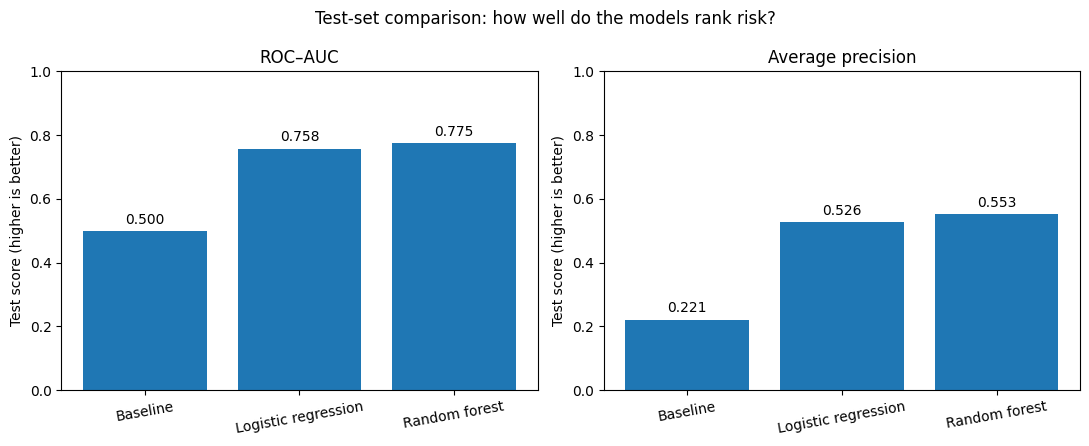

In [43]:
models = list(model_probabilities)
roc_scores = test_comparison["Test ROC-AUC"].to_numpy()
ap_scores = test_comparison["Test average precision"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, title, scores in zip(
    axes, ["ROC–AUC", "Average precision"], [roc_scores, ap_scores]
):
    bars = ax.bar(models, scores)
    ax.set(xlabel="", ylabel="Test score (higher is better)",
           title=title, ylim=(0, 1))
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.tick_params(axis="x", labelrotation=10)

fig.suptitle("Test-set comparison: how well do the models rank risk?")
plt.tight_layout()
plt.show()

### 7.6 Final comparison: reviewing the highest-risk 20%

The previous chart measures ranking quality. Here I use the same illustrative **20% review capacity** on the test set to see what the rankings mean in terms of customer outcomes. The majority baseline can't rank a top-risk group because it gives everyone the same score, so it is excluded from this figure.

,Model,Customers flagged,Defaults caught,False alarms,Defaults missed,Precision,Recall
0,Logistic regression,1200,649,551,678,0.541,0.489
1,Random forest,1200,676,524,651,0.563,0.509


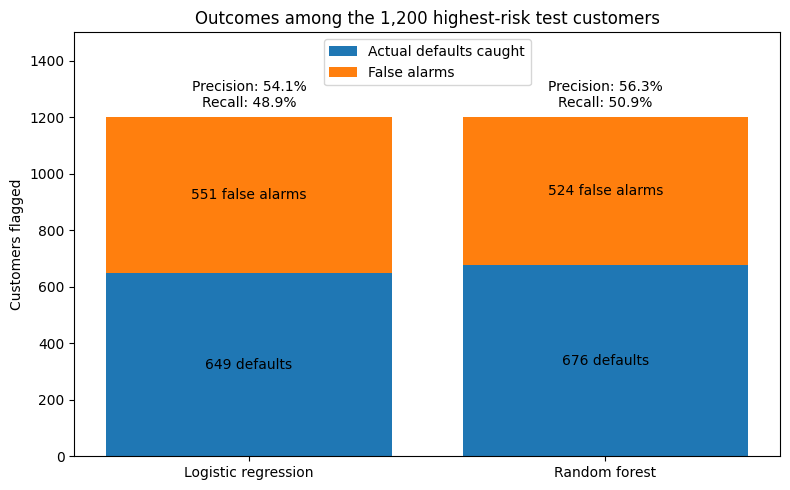

In [44]:
test_rankings = pd.DataFrame({
    "actual_default": y_test.to_numpy(),
    "logistic_score": logistic_test_probabilities,
    "forest_score": forest_test_probabilities
})
number_to_review_test = int(len(test_rankings) * 0.20)
total_test_defaults = int(test_rankings["actual_default"].sum())

outcome_rows = []
for model_name, score_column in [
    ("Logistic regression", "logistic_score"),
    ("Random forest", "forest_score")
]:
    flagged = test_rankings.nlargest(number_to_review_test, score_column)
    defaults_caught = int(flagged["actual_default"].sum())
    outcome_rows.append({
        "Model": model_name,
        "Customers flagged": number_to_review_test,
        "Defaults caught": defaults_caught,
        "False alarms": number_to_review_test - defaults_caught,
        "Defaults missed": total_test_defaults - defaults_caught,
        "Precision": defaults_caught / number_to_review_test,
        "Recall": defaults_caught / total_test_defaults
    })

test_outcomes = pd.DataFrame(outcome_rows)
display(test_outcomes.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
caught = ax.bar(test_outcomes["Model"], test_outcomes["Defaults caught"],
                label="Actual defaults caught")
false_alarms = ax.bar(
    test_outcomes["Model"], test_outcomes["False alarms"],
    bottom=test_outcomes["Defaults caught"], label="False alarms"
)
ax.bar_label(caught,
             labels=[f"{v} defaults" for v in test_outcomes["Defaults caught"]],
             label_type="center")
ax.bar_label(false_alarms,
             labels=[f"{v} false alarms" for v in test_outcomes["False alarms"]],
             label_type="center")
for i, row in test_outcomes.iterrows():
    ax.text(i, number_to_review_test + 35,
            f"Precision: {row['Precision']:.1%}\nRecall: {row['Recall']:.1%}",
            ha="center")
ax.set_ylim(0, number_to_review_test * 1.25)
ax.set(ylabel="Customers flagged", title="Outcomes among the 1,200 highest-risk test customers")
ax.legend()
plt.tight_layout()
plt.show()

In the top **1,200** test customers flagged by each model, logistic regression found **649 defaults** and generated **551 false alarms**. The forest found **676 defaults** and generated **524 false alarms**, which is **27 more true defaults and 27 fewer false alarms**, with exactly the same review workload.

The forest's precision was **56.3%** vs **54.1%**, and recall was **50.9%** vs **48.9%**. It's a fairly small practical improvement, but importantly, it goes in the same direction as the cross-validation results.

## 8. Conclusion and limitations

My first takeaway was that **accuracy is a weak headline measure for this dataset**: the majority baseline achieved about 78% simply by predicting no default. Logistic regression was better, and L1 regularisation let me cut the number of non-zero encoded coefficients from **62 to 36** without much change in validation ROC–AUC. That showed how useful model simplicity can be.

The confusion matrix was the turning point. The logistic model had reasonable overall scores, but it was missing most defaults at the standard threshold. Lowering that threshold caught more, with an obvious increase in false alarms. A random forest then improved the ranking itself, reaching **0.775 test ROC–AUC** and **0.553 test average precision**. Under the illustrative top-20% review rule, it caught **27 more defaults** than logistic regression in the test set.

I wouldn't claim the forest is automatically the better option in a real bank. The gain is modest, its predictions are harder to interpret, and the right decision threshold depends on the cost of missed defaults vs false alarms. There are also major limits to this study: the data are **historical and from Taiwan**, I haven't tested performance on current customers, and I haven't carried out a fairness or probability-calibration assessment. The test data were inspected partway through the investigation, so this final model comparison isn't fully blind.

### Source and reproducibility

**Dataset:** Yeh, I-C. and Lien, C-H. (2009), *The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients*, Expert Systems with Applications. Dataset available via the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) (ID 350).

To reproduce the analysis, open the notebook in Google Colab and use **Runtime → Run all**, or install the packages in `requirements.txt` in a Python environment. The UCI dataset is downloaded through `ucimlrepo`; no separate CSV is needed. The random seeds and cross-validation folds are fixed where relevant, although small numerical differences between package versions are possible.